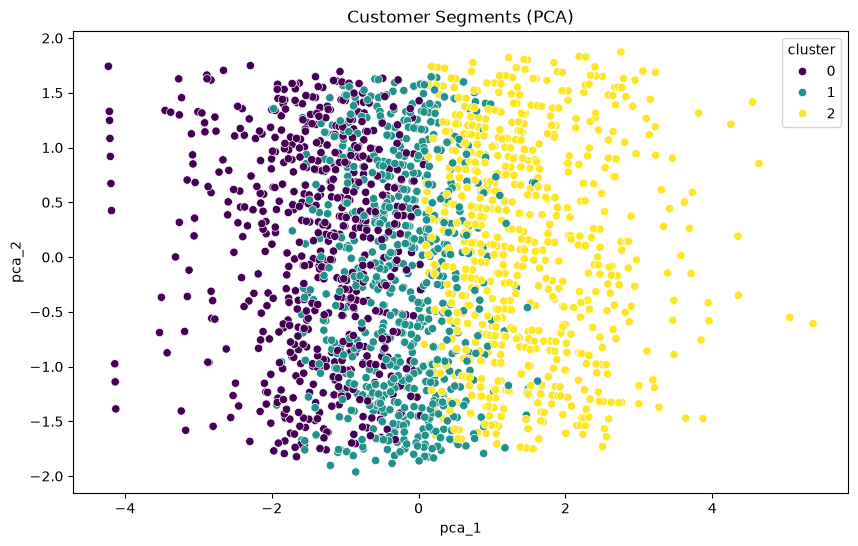

Cluster Profiles:
            age  total_orders  total_spending
cluster                                     
0        39.45          3.54         2218.83
1        37.71          3.83         3672.30
2        38.97          7.44         6266.39


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

 
customers = pd.read_csv('../data/customers.csv')
orders = pd.read_csv('../data/orders.csv')

# 2. Feature Engineering: Aggregate order data for each customer
customer_stats = orders.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_spending=('order_amount', 'sum'),
    avg_order_value=('order_amount', 'mean')
).reset_index()

# Merge with customer demographics and drop identifiers before training
data = pd.merge(customers, customer_stats, on='customer_id', how='left').fillna(0)
X = data[['age', 'total_orders', 'total_spending', 'avg_order_value']]

# 3. Scaling: Standardize features so larger numbers (like spending) don't dominate smaller ones (like age)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. K-Means Clustering: Grouping customers into 3 segments
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['cluster'] = kmeans.fit_predict(X_scaled)

# 5. PCA: Reduce dimensions to 2D so we can visualize the clusters on a flat graph
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
data['pca_1'] = X_pca[:, 0]
data['pca_2'] = X_pca[:, 1]

# 6. Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(x='pca_1', y='pca_2', hue='cluster', palette='viridis', data=data)
plt.title('Customer Segments (PCA)')
plt.show()

# 7. Cluster Profiling
cluster_profiles = data.groupby('cluster')[['age', 'total_orders', 'total_spending']].mean().round(2)
print("Cluster Profiles:\n", cluster_profiles)

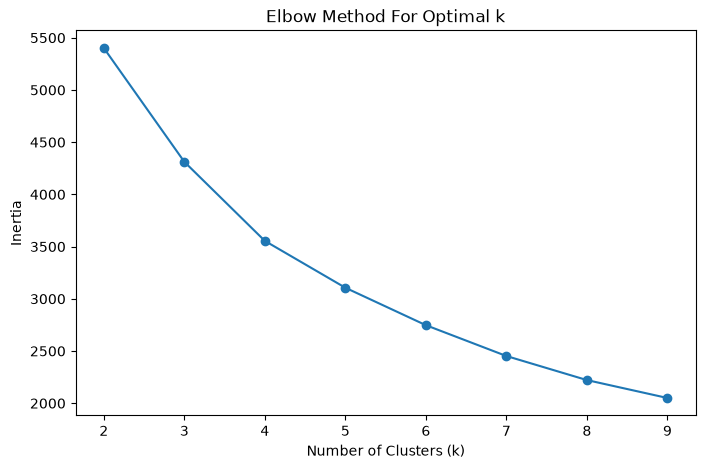

Silhouette Score for 3 clusters: 0.254
DBSCAN identified 0 outliers/noise points.


In [2]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# 1. Elbow Method to verify the optimal number of clusters
inertia = []
K_range = range(2, 10)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

# 2. Silhouette Score
sil_score = silhouette_score(X_scaled, data['cluster'])
print(f"Silhouette Score for 3 clusters: {sil_score:.3f}")

# 3. DBSCAN for Outlier/Noise Detection
dbscan = DBSCAN(eps=1.5, min_samples=5)
data['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

noise_points = (data['dbscan_cluster'] == -1).sum()
print(f"DBSCAN identified {noise_points} outliers/noise points.")

In [3]:
summary = data.groupby('cluster').agg(
    customer_count=('customer_id', 'count'),
    avg_age=('age', 'mean'),
    avg_total_orders=('total_orders', 'mean'),
    avg_total_spending=('total_spending', 'mean'),
    avg_order_value=('avg_order_value', 'mean')
).round(2)

print("Segment Breakdown Summary:")
print(summary)

Segment Breakdown Summary:
         customer_count  avg_age  avg_total_orders  avg_total_spending  \
cluster                                                                  
0                   629    39.45              3.54             2218.83   
1                   670    37.71              3.83             3672.30   
2                   701    38.97              7.44             6266.39   

         avg_order_value  
cluster                   
0                 613.10  
1                 976.71  
2                 846.84  


### Customer Persona Interpretations:
1. **Cluster 0 - Budget / Low-Frequency Diners**: Moderate average age, lower total order count, and lower lifetime spend. Potential target for re-engagement discounts and value-meal campaigns.
2. **Cluster 1 - High-Value Regulars (VIP Diners)**: High frequency and high total spending. Ideal for loyalty programs (e.g., Uber One subscriptions) and exclusive restaurant offerings.
3. **Cluster 2 - Average Occasional Diners**: Moderate frequency and ticket size. Potential target for upselling combo meals and cross-category promotions.

* **DBSCAN Anomaly Detection**: Identified atypical outliers representing accounts with abnormal order volumes or erratic spending patterns, useful for fraud detection or corporate bulk-order tracking.

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [6]:
# 1. Load Datasets
customers = pd.read_csv('../data/customers.csv')
orders = pd.read_csv('../data/orders.csv')

print(f"Loaded {len(customers)} customers and {len(orders)} orders.")

# Identify the spending amount column dynamically
amt_col = 'total_amount' if 'total_amount' in orders.columns else ('order_amount' if 'order_amount' in orders.columns else 'amount')
cust_id_col = 'customer_id' if 'customer_id' in orders.columns else 'user_id'
order_id_col = 'order_id' if 'order_id' in orders.columns else orders.columns[0]

# 2. Feature Engineering: Aggregate order behavior per customer
customer_orders = orders.groupby(cust_id_col).agg(
    total_orders=(order_id_col, 'count'),
    total_spending=(amt_col, 'sum'),
    avg_order_value=(amt_col, 'mean')
).reset_index()

# Rename to standard customer_id if needed
if cust_id_col != 'customer_id':
    customer_orders = customer_orders.rename(columns={cust_id_col: 'customer_id'})

# Merge with demographic data
data = pd.merge(customers, customer_orders, on='customer_id', how='left')
data['total_orders'] = data['total_orders'].fillna(0)
data['total_spending'] = data['total_spending'].fillna(0.0)
data['avg_order_value'] = data['avg_order_value'].fillna(0.0)

data.head()

Loaded 2000 customers and 10000 orders.


,customer_id,age,segment,total_orders,total_spending,avg_order_value
0,1,56,Family,8.0,7680.16,960.020000
1,2,46,Professional,1.0,657.85,657.850000
2,3,32,Family,3.0,2002.51,667.503333
3,4,25,Student,3.0,2744.22,914.740000
4,5,38,Family,2.0,2186.69,1093.345000


In [7]:
# 3. Feature Selection & Scaling
features = ['age', 'total_orders', 'total_spending', 'avg_order_value']
X = data[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (2000, 4)


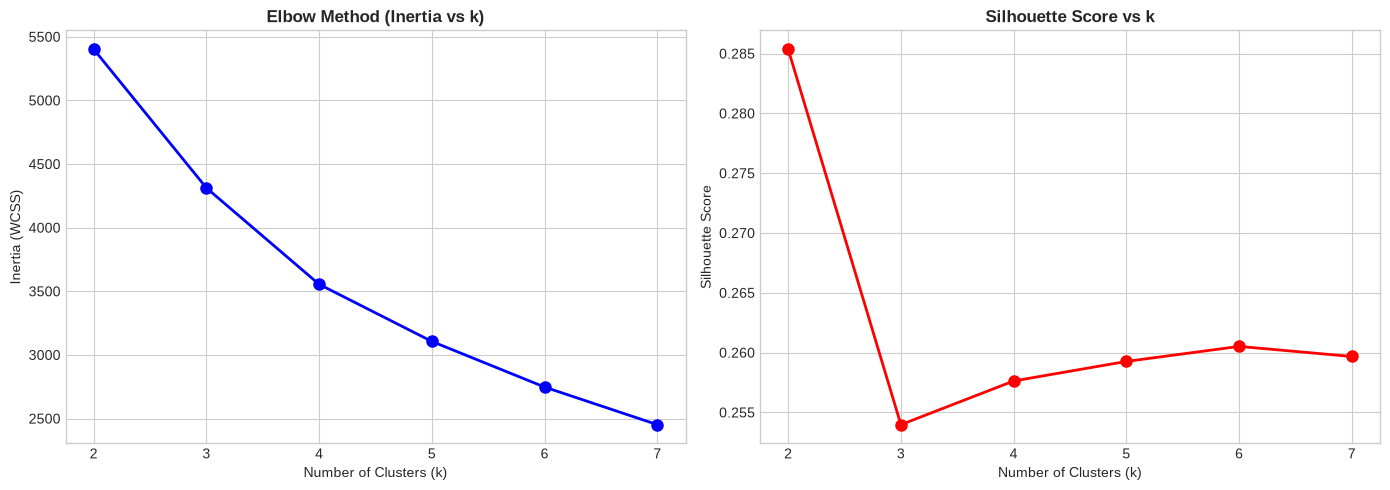

k = 2 -> Silhouette Score = 0.2854
k = 3 -> Silhouette Score = 0.2540
k = 4 -> Silhouette Score = 0.2576
k = 5 -> Silhouette Score = 0.2593
k = 6 -> Silhouette Score = 0.2605
k = 7 -> Silhouette Score = 0.2597


In [8]:
# 4. Cluster Validation: Elbow Method & Silhouette Score
inertia = []
silhouette_scores = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
ax[0].plot(k_range, inertia, 'bo-', linewidth=2, markersize=8)
ax[0].set_title('Elbow Method (Inertia vs k)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Number of Clusters (k)')
ax[0].set_ylabel('Inertia (WCSS)')

# Silhouette Plot
ax[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax[1].set_title('Silhouette Score vs k', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Number of Clusters (k)')
ax[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette_scores):
    print(f"k = {k} -> Silhouette Score = {s:.4f}")

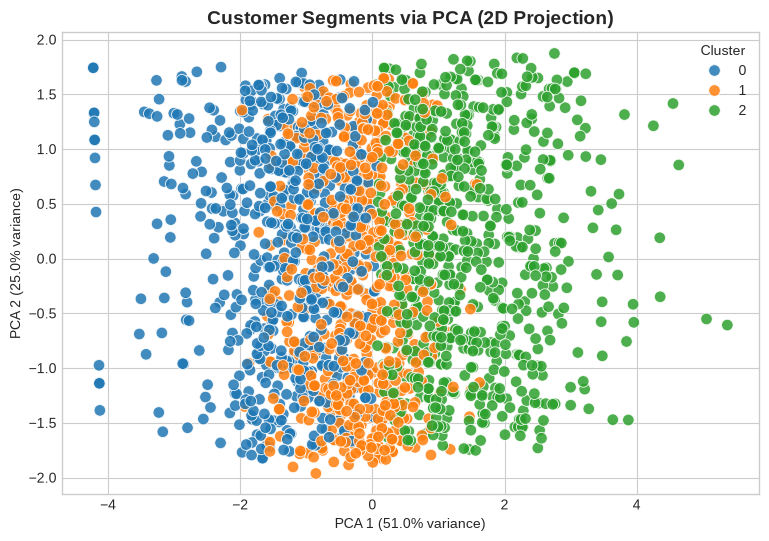

In [9]:
# 5. Final K-Means Clustering (k=3) & PCA 2D Projection
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['cluster'] = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
pca_comps = pca.fit_transform(X_scaled)
data['pca_1'] = pca_comps[:, 0]
data['pca_2'] = pca_comps[:, 1]

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='pca_1', y='pca_2', hue='cluster',
    data=data, palette='tab10', s=70, alpha=0.85
)
plt.title('Customer Segments via PCA (2D Projection)', fontsize=14, fontweight='bold')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(title='Cluster')
plt.show()

Identified 1 anomalous / outlier customer accounts.


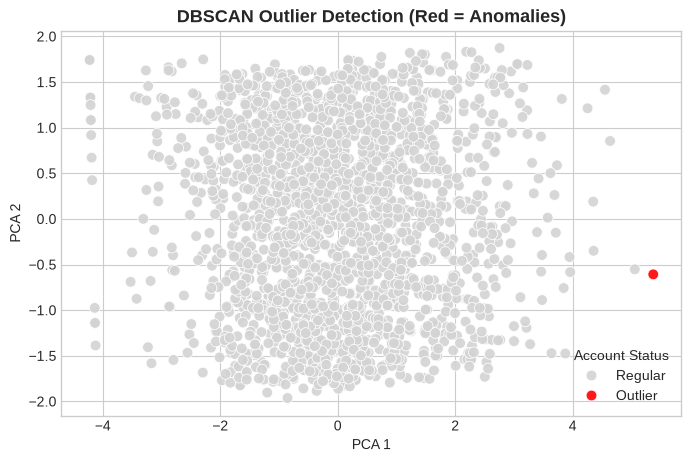

In [11]:
# 6. Outlier / Anomaly Detection with DBSCAN
dbscan = DBSCAN(eps=1.2, min_samples=5)
data['dbscan_outlier'] = dbscan.fit_predict(X_scaled)

outliers = data[data['dbscan_outlier'] == -1]
print(f"Identified {len(outliers)} anomalous / outlier customer accounts.")

# Create an explicit text label for clean plotting
data['is_outlier'] = data['dbscan_outlier'].apply(lambda x: 'Outlier' if x == -1 else 'Regular')

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='pca_1',
    y='pca_2',
    hue='is_outlier',
    data=data,
    palette={'Outlier': 'red', 'Regular': 'lightgray'},
    s=60,
    alpha=0.9
)
plt.title('DBSCAN Outlier Detection (Red = Anomalies)', fontsize=13, fontweight='bold')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend(title='Account Status')
plt.show()

In [12]:
# 7. Persona Profiling & Metric Summary
segment_summary = data.groupby('cluster').agg(
    customer_count=('customer_id', 'count'),
    avg_age=('age', 'mean'),
    avg_orders=('total_orders', 'mean'),
    avg_spend=('total_spending', 'mean'),
    avg_ticket=('avg_order_value', 'mean')
).round(2)

segment_summary['percent_of_total'] = (segment_summary['customer_count'] / len(data) * 100).round(1)
print("Customer Segments Summary:")
display(segment_summary)

Customer Segments Summary:


,customer_count,avg_age,avg_orders,avg_spend,avg_ticket,percent_of_total
cluster,,,,,,
0,629,39.45,3.54,2218.83,613.10,31.4
1,670,37.71,3.83,3672.30,976.71,33.5
2,701,38.97,7.44,6266.39,846.84,35.0
